In [1]:
import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
url = "https://github.com/Ebuka24Stephen/trashnet-dataset/archive/refs/heads/main.zip"
zip_path = "/content/waste_dataset.zip"
extract_path = "/content/waste_data"

response = requests.get(url, timeout=120)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

class_names_expected = {
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
}

data_dir = None

for folder in Path(extract_path).rglob("*"):
    if folder.is_dir():
        subdirs = {
            p.name.lower()
            for p in folder.iterdir()
            if p.is_dir()
        }
        if class_names_expected.issubset(subdirs):
            data_dir = str(folder)
            break

if data_dir is None:
    raise FileNotFoundError(
        "Could not find all six class folders. "
        "Check the dataset download and directory structure."
    )

print("Dataset directory:", data_dir)

for cls in sorted(class_names_expected):
    folder = Path(data_dir) / cls
    count = sum(
        1 for f in folder.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    )
    print(f"{cls}: {count} images")

Dataset directory: /content/waste_data/trashnet-dataset-main
cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images


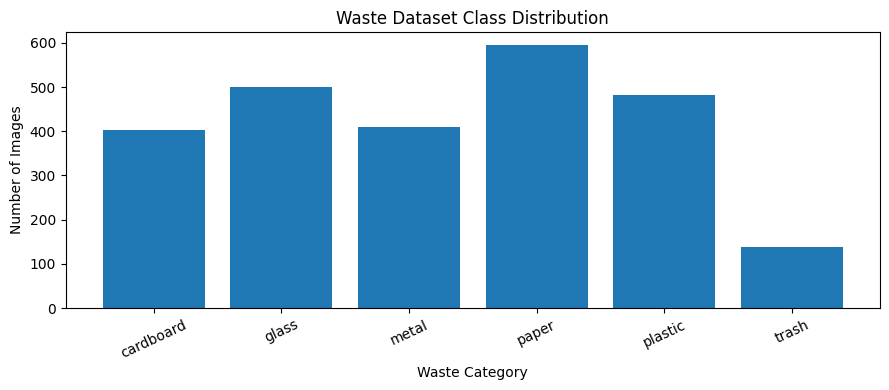

In [3]:
class_counts = {}

for cls in sorted(class_names_expected):
    folder = Path(data_dir) / cls
    class_counts[cls] = sum(
        1 for f in folder.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    )

plt.figure(figsize=(9, 4))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Waste Dataset Class Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

class_names = train_ds.class_names

n_batches = tf.data.experimental.cardinality(temp_ds).numpy()

val_ds = temp_ds.take(n_batches // 2)
test_ds = temp_ds.skip(n_batches // 2)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Found 2527 files belonging to 6 classes.
Using 1769 files for training.
Found 2527 files belonging to 6 classes.
Using 758 files for validation.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Training batches: 56
Validation batches: 12
Testing batches: 12


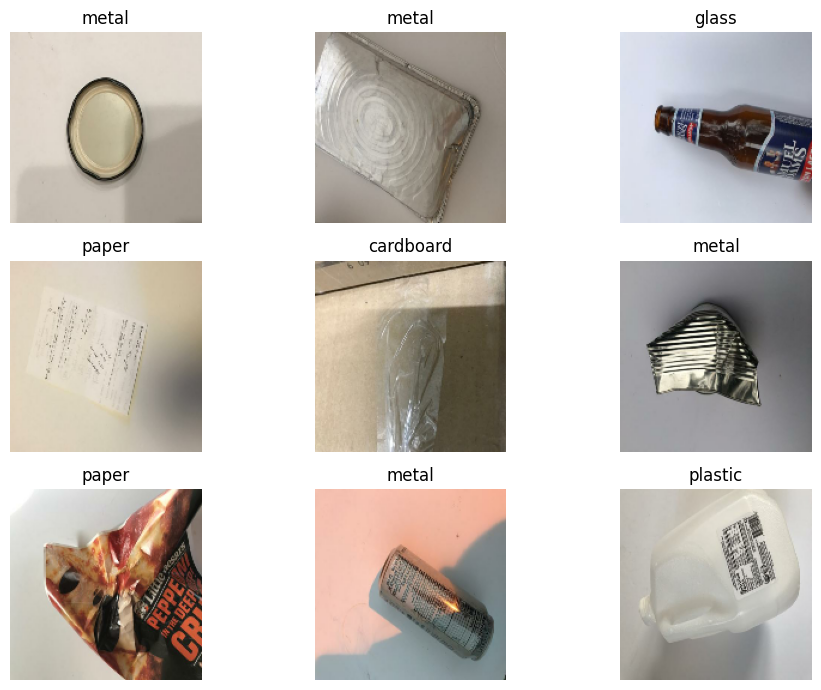

In [5]:
plt.figure(figsize=(10, 7))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(*IMG_SIZE, 3)),
    augmentation,
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(len(class_names), activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.2335 - loss: 1.7278 - val_accuracy: 0.2292 - val_loss: 1.6900
Epoch 2/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.3313 - loss: 1.5930 - val_accuracy: 0.3776 - val_loss: 1.5523
Epoch 3/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.3607 - loss: 1.5202 - val_accuracy: 0.4297 - val_loss: 1.5435
Epoch 4/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.4098 - loss: 1.4663 - val_accuracy: 0.3750 - val_loss: 1.4465
Epoch 5/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.4047 - loss: 1.4323 - val_accuracy: 0.4349 - val_loss: 1.3593
Epoch 6/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.4438 - loss: 1.3750 - val_accuracy: 0.5026 - val_loss: 1.3238
Epoch 7/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.4765 - loss: 1.3035 - val_accuracy: 0.5234 - val_loss: 1.2485
Epoch 8/8
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.4975 - loss: 1.2694 - val_accuracy: 0.5391 - val_loss

In [7]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

x = augmentation(inputs)
x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    len(class_names), activation="softmax"
)(x)

mobilenet_model = tf.keras.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

mobile_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.4895 - loss: 1.3920 - val_accuracy: 0.7057 - val_loss: 0.8391
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.6908 - loss: 0.8151 - val_accuracy: 0.7604 - val_loss: 0.6985
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.7626 - loss: 0.6684 - val_accuracy: 0.7578 - val_loss: 0.6525
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.7778 - loss: 0.6133 - val_accuracy: 0.7734 - val_loss: 0.6392
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.7965 - loss: 0.5736 - val_accuracy: 0.7995 - val_loss: 0.5693


In [8]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/3
56/56 ━━━━━━━━━━━━━━━━━━━━ 14s 96ms/step - accuracy: 0.6970 - loss: 0.8499 - val_accuracy: 0.7969 - val_loss: 0.5386
Epoch 2/3
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.7377 - loss: 0.7247 - val_accuracy: 0.8203 - val_loss: 0.5359
Epoch 3/3
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.7609 - loss: 0.6848 - val_accuracy: 0.7969 - val_loss: 0.5457


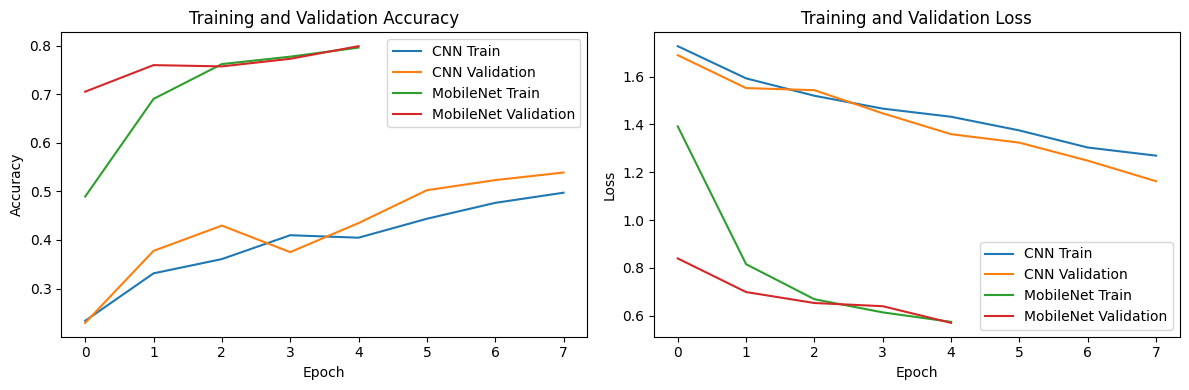

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="CNN Train")
plt.plot(cnn_history.history["val_accuracy"], label="CNN Validation")
plt.plot(mobile_history.history["accuracy"], label="MobileNet Train")
plt.plot(mobile_history.history["val_accuracy"], label="MobileNet Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="CNN Train")
plt.plot(cnn_history.history["val_loss"], label="CNN Validation")
plt.plot(mobile_history.history["loss"], label="MobileNet Train")
plt.plot(mobile_history.history["val_loss"], label="MobileNet Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Baseline CNN classification report
              precision    recall  f1-score   support

   cardboard       0.16      0.24      0.19        45
       glass       0.15      0.16      0.16        69
       metal       0.16      0.10      0.12        69
       paper       0.28      0.37      0.32        99
     plastic       0.14      0.12      0.13        68
       trash       0.00      0.00      0.00        24

    accuracy                           0.20       374
   macro avg       0.15      0.17      0.15       374
weighted avg       0.18      0.20      0.18       374



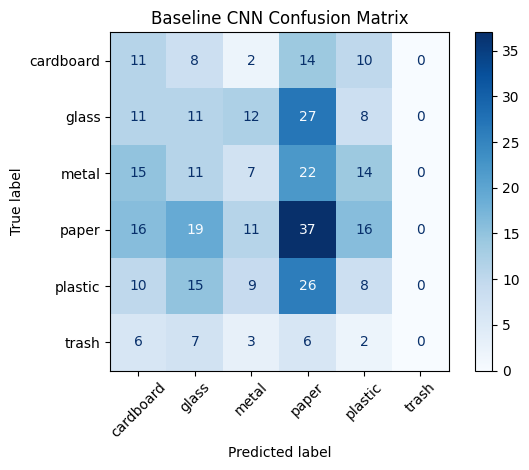


MobileNetV2 classification report
              precision    recall  f1-score   support

   cardboard       0.21      0.23      0.22        52
       glass       0.16      0.16      0.16        74
       metal       0.20      0.25      0.22        61
       paper       0.25      0.24      0.25        88
     plastic       0.21      0.18      0.19        74
       trash       0.05      0.04      0.04        25

    accuracy                           0.20       374
   macro avg       0.18      0.18      0.18       374
weighted avg       0.20      0.20      0.20       374



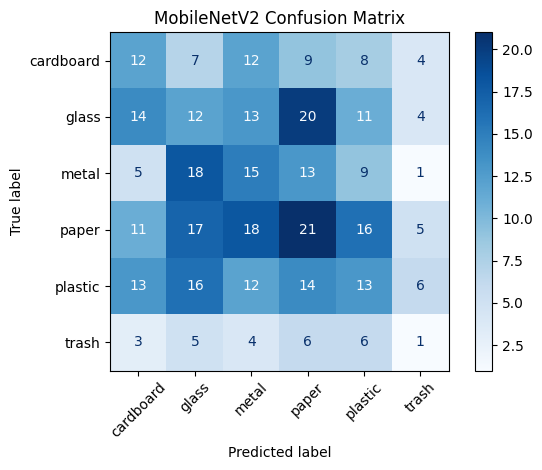

       Model  Accuracy  Precision  Recall  F1-score
Baseline CNN    0.1979     0.1486  0.1661    0.1536
 MobileNetV2    0.1979     0.1794  0.1822    0.1801


In [10]:
def evaluate_model(model, dataset, model_name):
    y_true = np.concatenate([
        labels.numpy() for _, labels in dataset
    ])

    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    print(f"\n{model_name} classification report")
    print(classification_report(
        y_true, y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(
            y_true, y_pred, labels=range(len(class_names))
        ),
        display_labels=class_names
    ).plot(cmap="Blues", xticks_rotation=45)

    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return results


cnn_results = evaluate_model(cnn_model, test_ds, "Baseline CNN")
mobile_results = evaluate_model(
    mobilenet_model, test_ds, "MobileNetV2"
)

comparison = pd.DataFrame([cnn_results, mobile_results])
print(comparison.round(4).to_string(index=False))

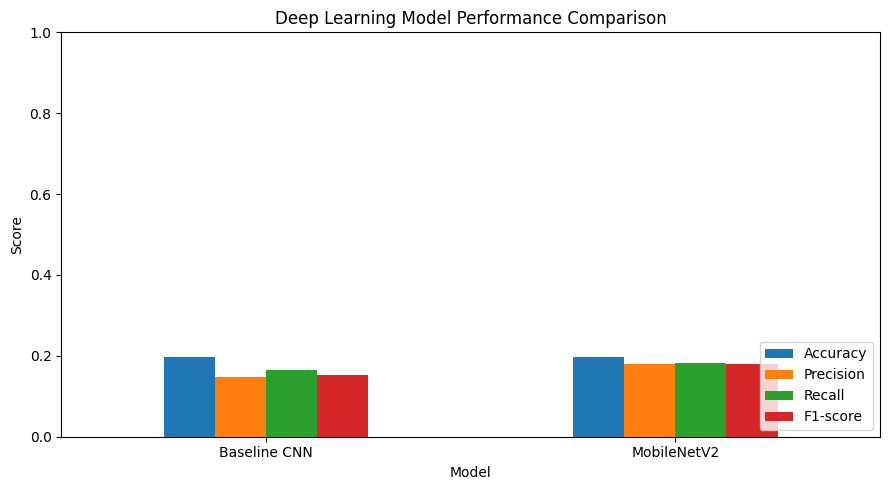

In [11]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(9, 5), ylim=(0, 1))

plt.title("Deep Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Saving Cardboard boxes for recycling_.jpeg to Cardboard boxes for recycling_.jpeg


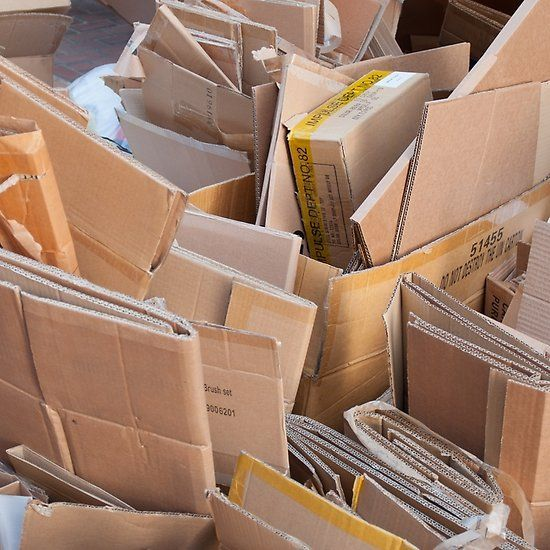

Predicted waste category: cardboard
Model confidence: 99.12%


In [12]:
from google.colab import files
from PIL import Image
from IPython.display import display
import numpy as np

# Fallback definitions in case preceding cells were not executed
try:
    IMG_SIZE
except NameError:
    IMG_SIZE = (160, 160)

try:
    class_names
except NameError:
    class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    display(image)

    resized = image.resize(IMG_SIZE)
    image_array = np.array(resized, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = mobilenet_model.predict(
        image_array, verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index]) * 100

    print("Predicted waste category:", predicted_class)
    print(f"Model confidence: {confidence:.2f}%")

In [13]:
cnn_model.save("/content/waste_cnn.keras")
mobilenet_model.save("/content/waste_mobilenetv2.keras")

print("Both trained models have been saved.")

Both trained models have been saved.


In [14]:
from google.colab import files

files.download("/content/waste_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>